# Resume–Job Fit
## Classification: Traditional vs. Pretrained Representations
### ARTI 404 – Natural Language Processing

In [15]:
#%pip install pandas numpy scikit-learn datasets sentence-transformers matplotlib

#### 1. Setup

In [16]:
import random
import numpy as np
import pandas as pd
from datasets import load_dataset

# Fix the random seed so results are reproducible on every run
SEED = 42
# Regularization values tried for both methods
C_GRID = [0.001, 0.003, 0.01, 0.1, 1, 10]
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_colwidth", 120)

#### 2. Data

In [17]:
# Load the dataset from Hugging Face
raw = load_dataset("cnamuangtoun/resume-job-description-fit")

# Merge the original train and test parts into one table,
# because we will create our own resume-based split later
df = pd.concat(
    [raw["train"].to_pandas(), raw["test"].to_pandas()],
    ignore_index=True
)

print("Shape:", df.shape)
df.head()

Shape: (8000, 3)


,resume_text,job_description_text,label
0,SummaryHighly motivated Sales Associate with extensive customer service and sales experience. Outgoing sales profess...,Net2Source Inc. is an award-winning total workforce solutions company recognized by Staffing Industry Analysts for o...,No Fit
1,Professional SummaryCurrently working with Caterpillar as an contract employee Active in several NPI and CPI project...,At Salas OBrien we tell our clients that were engineered for impact. This passion for making a difference applies ju...,No Fit
2,"SummaryI started my construction career in June of 2017 in Jacksonville, Florida as an Electrical Apprentice working...",Schweitzer Engineering Laboratories (SEL) Infrastructure Defense Division seeks a talented individual for a cybersec...,No Fit
3,SummaryCertified Electrical Foremanwith thirteen years of experience in the implementation of electrical systems on ...,"Mizick Miller & Company, Inc. is looking for a dynamic individual to join our team!This is a great opportunity for t...",No Fit
4,SummaryWith extensive experience in business/requirement analysis with SDLC processing. Experience includes project ...,Life at Capgemini\nCapgemini supports all aspects of your well-being throughout the changing stages of your life and...,No Fit


In [18]:
# Class counts
print("Label counts:")
print(df["label"].value_counts(), "\n")

# Unique resumes and job descriptions
print("Unique resumes:", df["resume_text"].nunique())
print("Unique job descriptions:", df["job_description_text"].nunique(), "\n")

# Empty texts and fully duplicated rows
print("Empty resumes:", (df["resume_text"].str.strip() == "").sum())
print("Empty job descriptions:", (df["job_description_text"].str.strip() == "").sum())
print("Duplicated rows:", df.duplicated().sum(), "\n")

# Text lengths in words
df["resume_len"] = df["resume_text"].str.split().str.len()
df["job_len"] = df["job_description_text"].str.split().str.len()
print(df[["resume_len", "job_len"]].describe().round(0))

Label counts:
label
No Fit           4000
Potential Fit    2000
Good Fit         2000
Name: count, dtype: int64 

Unique resumes: 643
Unique job descriptions: 351 

Empty resumes: 0
Empty job descriptions: 0
Duplicated rows: 1 

       resume_len  job_len
count      8000.0   8000.0
mean        704.0    378.0
std         387.0    250.0
min          84.0     11.0
25%         488.0    169.0
50%         618.0    326.0
75%         809.0    552.0
max        3134.0   1254.0


#### Resume-based split
All pairs that share the same resume are kept in the same split (train / dev / test), so the model is always tested on unseen resumes.

In [19]:
from sklearn.model_selection import GroupShuffleSplit

# Remove the single fully duplicated row
df = df.drop_duplicates().reset_index(drop=True)

# Give every unique resume an id, used as the group for splitting
df["resume_id"] = df["resume_text"].factorize()[0]

# First split: 70% train, 30% temporary (by resume)
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=SEED)
train_idx, temp_idx = next(gss.split(df, groups=df["resume_id"]))
train_df = df.iloc[train_idx].reset_index(drop=True)
temp_df = df.iloc[temp_idx].reset_index(drop=True)

# Second split: the 30% is divided equally into dev and test (by resume)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=SEED)
dev_idx, test_idx = next(gss2.split(temp_df, groups=temp_df["resume_id"]))
dev_df = temp_df.iloc[dev_idx].reset_index(drop=True)
test_df = temp_df.iloc[test_idx].reset_index(drop=True)

# Sizes and label distribution of each split
for name, part in [("Train", train_df), ("Dev", dev_df), ("Test", test_df)]:
    print(f"{name}: {len(part)} pairs, {part['resume_id'].nunique()} resumes")
    print(part["label"].value_counts(normalize=True).round(2).to_dict(), "\n")

Train: 5683 pairs, 450 resumes
{'No Fit': 0.5, 'Good Fit': 0.25, 'Potential Fit': 0.25} 

Dev: 1208 pairs, 96 resumes
{'No Fit': 0.51, 'Good Fit': 0.25, 'Potential Fit': 0.23} 

Test: 1108 pairs, 97 resumes
{'No Fit': 0.49, 'Potential Fit': 0.27, 'Good Fit': 0.24} 



In [20]:
# Check that no resume appears in more than one split
train_r = set(train_df["resume_id"])
dev_r = set(dev_df["resume_id"])
test_r = set(test_df["resume_id"])
assert not (train_r & dev_r) and not (train_r & test_r) and not (dev_r & test_r)
print("No resume is shared between splits.")

# Job descriptions may repeat across splits (reported as a limitation)
train_j = set(train_df["job_description_text"])
test_jobs = test_df["job_description_text"]
print("Test pairs whose job description also appears in train:",
    test_jobs.isin(train_j).sum(), "of", len(test_df))

No resume is shared between splits.
Test pairs whose job description also appears in train: 1104 of 1108


#### Lexical overlap and the low-overlap subset
Overlap is measured with Jaccard similarity between the sets of normalized content words (lowercased, stop words removed) of each CV and its job description. The low-overlap threshold is chosen on the development set only.

In [21]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def normalize_text(text):
    # Split words that were glued together, e.g. "SummaryHighly" -> "Summary Highly"
    text = re.sub(r"([a-z])([A-Z])", r"\1 \2", text)
    # Lowercase and keep letters, numbers and spaces only
    text = re.sub(r"[^a-z0-9\s]", " ", text.lower())
    return re.sub(r"\s+", " ", text).strip()

def content_words(text):
    # Set of meaningful words: no stop words, no single characters
    return {w for w in normalize_text(text).split()
            if w not in ENGLISH_STOP_WORDS and len(w) > 1}

def jaccard(text_a, text_b):
    a, b = content_words(text_a), content_words(text_b)
    return len(a & b) / len(a | b) if (a | b) else 0.0

# Compute the overlap for every pair in each split
for part in [train_df, dev_df, test_df]:
    part["jaccard"] = [jaccard(r, j) for r, j in
                    zip(part["resume_text"], part["job_description_text"])]

# Average overlap per label in the training set
print(train_df.groupby("label")["jaccard"].mean().round(3))

label
Good Fit         0.076
No Fit           0.061
Potential Fit    0.066
Name: jaccard, dtype: float64


In [22]:
# Threshold = the 25th percentile of overlap in the development set
LOW_OVERLAP_THRESHOLD = dev_df["jaccard"].quantile(0.25)
print("Low-overlap threshold:", round(LOW_OVERLAP_THRESHOLD, 3))

# Apply the same threshold to the test set
test_df["low_overlap"] = test_df["jaccard"] <= LOW_OVERLAP_THRESHOLD
low_test_df = test_df[test_df["low_overlap"]].reset_index(drop=True)

print("Low-overlap test pairs:", len(low_test_df), "of", len(test_df))
print(low_test_df["label"].value_counts())

Low-overlap threshold: 0.047
Low-overlap test pairs: 294 of 1108
label
No Fit           174
Potential Fit     81
Good Fit          39
Name: count, dtype: int64


#### 3. Method 1: TF-IDF + Logistic Regression
Each pair is represented by: the TF-IDF vector of the CV, the TF-IDF vector of the job description, their element-wise product (shared weighted words), and two similarity scores (cosine similarity and Jaccard overlap). The TF-IDF vocabulary is learned from training texts only.

In [23]:
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

# Learn the TF-IDF vocabulary from training texts only
tfidf = TfidfVectorizer(
    preprocessor=normalize_text,
    stop_words="english",
    ngram_range=(1, 2),   # single words and two-word phrases
    min_df=2,             # ignore words that appear in only one text
    max_features=30000,
    sublinear_tf=True
)
train_texts = pd.concat([train_df["resume_text"],
                        train_df["job_description_text"]]).unique()
tfidf.fit(train_texts)

# The two similarity scores are scaled using training data only
sim_scaler = StandardScaler()

def tfidf_features(part, fit_scaler=False):
    R = tfidf.transform(part["resume_text"])
    J = tfidf.transform(part["job_description_text"])
    shared = R.multiply(J)  # shared weighted words

    # TF-IDF rows are normalized, so the row sum of R*J is the cosine similarity
    cosine = np.asarray(shared.sum(axis=1))
    sims = np.hstack([cosine, part[["jaccard"]].values])
    sims = sim_scaler.fit_transform(sims) if fit_scaler else sim_scaler.transform(sims)

    return hstack([R, J, shared, csr_matrix(sims)]).tocsr()

X_train_m1 = tfidf_features(train_df, fit_scaler=True)
X_dev_m1 = tfidf_features(dev_df)
y_train, y_dev = train_df["label"], dev_df["label"]

print("Vocabulary size:", len(tfidf.vocabulary_))
print("Feature matrix shape:", X_train_m1.shape)

Vocabulary size: 30000
Feature matrix shape: (5683, 90002)


In [24]:
# Try several settings and keep the one with the best macro F1 on the dev set
m1_results = []
for C in [0.01, 0.1, 1, 10]:
    for cw in [None, "balanced"]:
        model = LogisticRegression(C=C, class_weight=cw, max_iter=3000)
        model.fit(X_train_m1, y_train)
        pred = model.predict(X_dev_m1)
        m1_results.append({
            "C": C, "class_weight": cw, "model": model,
            "dev_accuracy": accuracy_score(y_dev, pred),
            "dev_macro_f1": f1_score(y_dev, pred, average="macro")
        })

m1_table = pd.DataFrame(m1_results).drop(columns="model")
print(m1_table.sort_values("dev_macro_f1", ascending=False).round(3).to_string(index=False))

best_m1 = max(m1_results, key=lambda r: r["dev_macro_f1"])
model_m1 = best_m1["model"]
print("\nSelected:", "C =", best_m1["C"], "| class_weight =", best_m1["class_weight"])

    C class_weight  dev_accuracy  dev_macro_f1
 1.00     balanced         0.574         0.574
10.00     balanced         0.576         0.573
 0.10     balanced         0.555         0.554
 1.00         None         0.570         0.544
10.00         None         0.564         0.541
 0.01     balanced         0.521         0.498
 0.10         None         0.579         0.494
 0.01         None         0.540         0.362

Selected: C = 1 | class_weight = balanced


#### 4. Method 2: Pretrained Sentence Embeddings + Logistic Regression
Each text is embedded with the pretrained all-MiniLM-L6-v2 model. Because the model reads about 256 tokens only, long texts are split into 150-word chunks; the chunk embeddings are averaged into one text embedding. Each pair is represented by the CV embedding (u), the job embedding (v), their product (u*v), their absolute difference (|u-v|) and their cosine similarity. The pretrained weights are frozen; only the Logistic Regression is trained, on training pairs only.

In [25]:
from sentence_transformers import SentenceTransformer

# Load the pretrained model (frozen, no fine-tuning)
encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
print("Max tokens per input:", encoder.max_seq_length)

def light_clean(text):
    # Fix glued words and extra spaces, but keep the natural sentence form
    text = re.sub(r"([a-z])([A-Z])", r"\1 \2", text)
    return re.sub(r"\s+", " ", text).strip()

def split_chunks(text, size=150):
    words = light_clean(text).split()
    return [" ".join(words[i:i + size]) for i in range(0, len(words), size)]

# Embed every unique text once (no labels are used here)
all_texts = pd.unique(pd.concat([df["resume_text"], df["job_description_text"]]))
chunks, owners = [], []
for i, text in enumerate(all_texts):
    for chunk in split_chunks(text):
        chunks.append(chunk)
        owners.append(i)
owners = np.array(owners)

chunk_emb = encoder.encode(chunks, batch_size=64,
                            show_progress_bar=True, normalize_embeddings=True)

# Average the chunks of each text, then normalize to unit length
text_emb = np.vstack([chunk_emb[owners == i].mean(axis=0)
                        for i in range(len(all_texts))])
text_emb = text_emb / np.linalg.norm(text_emb, axis=1, keepdims=True)
emb_lookup = dict(zip(all_texts, text_emb))

print("Texts:", len(all_texts), "| Chunks:", len(chunks), "| Embedding size:", text_emb.shape[1])

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Max tokens per input: 256


Batches:   0%|          | 0/72 [00:00<?, ?it/s]

Texts: 994 | Chunks: 4600 | Embedding size: 384


In [26]:
def embedding_features(part):
    U = np.vstack(part["resume_text"].map(emb_lookup))
    V = np.vstack(part["job_description_text"].map(emb_lookup))
    cosine = (U * V).sum(axis=1, keepdims=True)  # vectors are unit length
    return np.hstack([U, V, U * V, np.abs(U - V), cosine])

# Scale features using training data only
emb_scaler = StandardScaler()
X_train_m2 = emb_scaler.fit_transform(embedding_features(train_df))
X_dev_m2 = emb_scaler.transform(embedding_features(dev_df))
print("Feature matrix shape:", X_train_m2.shape)

Feature matrix shape: (5683, 1537)


In [28]:
# Same settings grid as Method 1, selected by macro F1 on the dev set
m2_results = []
for C in C_GRID:
        for cw in [None, "balanced"]:
            model = LogisticRegression(C=C, class_weight=cw, max_iter=3000)
            model.fit(X_train_m2, y_train)
            pred = model.predict(X_dev_m2)
            m2_results.append({
                "C": C, "class_weight": cw, "model": model,
                "dev_accuracy": accuracy_score(y_dev, pred),
                "dev_macro_f1": f1_score(y_dev, pred, average="macro")
            })

m2_table = pd.DataFrame(m2_results).drop(columns="model")
print(m2_table.sort_values("dev_macro_f1", ascending=False).round(3).to_string(index=False))

best_m2 = max(m2_results, key=lambda r: r["dev_macro_f1"])
model_m2 = best_m2["model"]
print("\nSelected:", "C =", best_m2["C"], "| class_weight =", best_m2["class_weight"])

     C class_weight  dev_accuracy  dev_macro_f1
 0.003     balanced         0.596         0.593
 0.003         None         0.607         0.589
 0.001     balanced         0.588         0.584
 0.010     balanced         0.585         0.581
 0.100     balanced         0.586         0.578
 0.010         None         0.594         0.577
 0.001         None         0.598         0.573
 0.100         None         0.580         0.564
 1.000     balanced         0.560         0.544
 1.000         None         0.555         0.534
10.000     balanced         0.521         0.501
10.000         None         0.522         0.499

Selected: C = 0.003 | class_weight = balanced


#### 5. Results
Both selected models are evaluated once on the same held-out test pairs: first on the full test set, then on the low-overlap subset.

In [29]:
import os

# Build test features with the already-fitted TF-IDF and scaler (no refitting)
X_test_m1 = tfidf_features(test_df)
X_test_m2 = emb_scaler.transform(embedding_features(test_df))

# Store predictions next to each test pair (used later for error analysis)
test_df["pred_m1"] = model_m1.predict(X_test_m1)
test_df["pred_m2"] = model_m2.predict(X_test_m2)

methods = [("Method 1: TF-IDF + LR", "pred_m1"),
            ("Method 2: MiniLM + LR", "pred_m2")]
subsets = [("Full test", pd.Series(True, index=test_df.index)),
            ("Low-overlap subset", test_df["low_overlap"])]

rows = []
for method_name, pred_col in methods:
    for subset_name, mask in subsets:
        y_true = test_df.loc[mask, "label"]
        y_pred = test_df.loc[mask, pred_col]
        rows.append({
            "Method": method_name,
            "Test data": subset_name,
            "Pairs": int(mask.sum()),
            "Accuracy": accuracy_score(y_true, y_pred),
            "Macro F1": f1_score(y_true, y_pred, average="macro")
        })

results = pd.DataFrame(rows)
print(results.round(3).to_string(index=False))

# Save the results so they can be checked against the report
os.makedirs("results", exist_ok=True)
results.round(4).to_csv("results/test_results.csv", index=False)

               Method          Test data  Pairs  Accuracy  Macro F1
Method 1: TF-IDF + LR          Full test   1108     0.644     0.645
Method 1: TF-IDF + LR Low-overlap subset    294     0.650     0.611
Method 2: MiniLM + LR          Full test   1108     0.625     0.627
Method 2: MiniLM + LR Low-overlap subset    294     0.599     0.557


#### Confusion matrices and per-class results
Rows are the true labels and columns are the predicted labels. The per-class table shows which fit levels each method handles well or poorly, on the full test set and on the low-overlap subset.

Saved: results/cm_method1_tfidf_full_test.png
Saved: results/cm_method1_tfidf_low_overlap.png
Saved: results/cm_method2_minilm_full_test.png
Saved: results/cm_method2_minilm_low_overlap.png


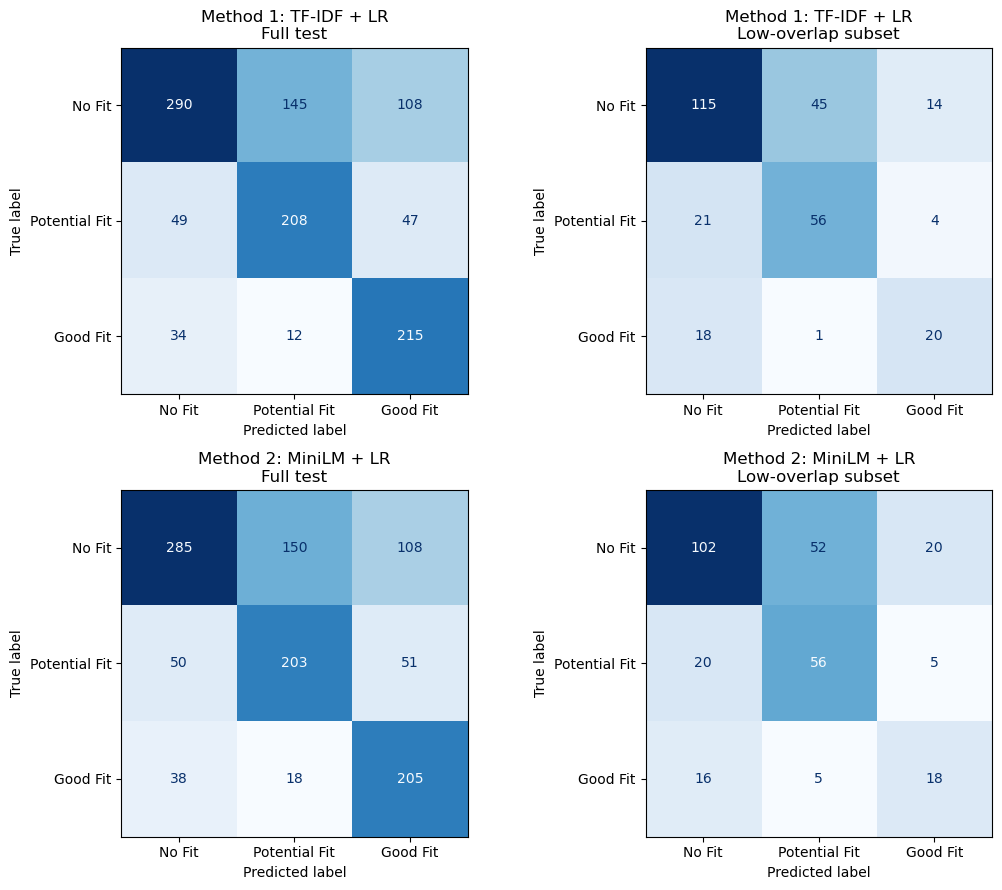

In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, recall_score

LABELS = ["No Fit", "Potential Fit", "Good Fit"]
os.makedirs("results", exist_ok=True)

# Short names used in the image file names
file_names = {"pred_m1": "method1_tfidf", "pred_m2": "method2_minilm",
                "Full test": "full_test", "Low-overlap subset": "low_overlap"}

# 1) Save each confusion matrix as a separate image
for method_name, pred_col in methods:
    for subset_name, mask in subsets:
        fig, ax = plt.subplots(figsize=(6, 5))
        ConfusionMatrixDisplay.from_predictions(
            test_df.loc[mask, "label"], test_df.loc[mask, pred_col],
            labels=LABELS, ax=ax, colorbar=False, cmap="Blues"
        )
        ax.set_title(f"{method_name}\n{subset_name}")
        plt.tight_layout()
        path = f"results/cm_{file_names[pred_col]}_{file_names[subset_name]}.png"
        plt.savefig(path, dpi=200)
        plt.close(fig)  # do not display it here
        print("Saved:", path)

# 2) Save and display all four matrices together
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for r, (method_name, pred_col) in enumerate(methods):
    for c, (subset_name, mask) in enumerate(subsets):
        ConfusionMatrixDisplay.from_predictions(
            test_df.loc[mask, "label"], test_df.loc[mask, pred_col],
            labels=LABELS, ax=axes[r, c], colorbar=False, cmap="Blues"
        )
        axes[r, c].set_title(f"{method_name}\n{subset_name}")

plt.tight_layout()
plt.savefig("results/confusion_matrices_all.png", dpi=200)
plt.show()

In [32]:
# Per-class F1 and recall for each method on each test set
rows = []
for method_name, pred_col in methods:
    for subset_name, mask in subsets:
        y_true = test_df.loc[mask, "label"]
        y_pred = test_df.loc[mask, pred_col]
        f1s = f1_score(y_true, y_pred, labels=LABELS, average=None)
        recalls = recall_score(y_true, y_pred, labels=LABELS, average=None)
        for label, f1, rec in zip(LABELS, f1s, recalls):
            rows.append({"Method": method_name, "Test data": subset_name,
                        "Label": label, "F1": f1, "Recall": rec})

per_class = pd.DataFrame(rows)
print(per_class.round(3).to_string(index=False))
per_class.round(4).to_csv("results/per_class_results.csv", index=False)

               Method          Test data         Label    F1  Recall
Method 1: TF-IDF + LR          Full test        No Fit 0.633   0.534
Method 1: TF-IDF + LR          Full test Potential Fit 0.622   0.684
Method 1: TF-IDF + LR          Full test      Good Fit 0.681   0.824
Method 1: TF-IDF + LR Low-overlap subset        No Fit 0.701   0.661
Method 1: TF-IDF + LR Low-overlap subset Potential Fit 0.612   0.691
Method 1: TF-IDF + LR Low-overlap subset      Good Fit 0.519   0.513
Method 2: MiniLM + LR          Full test        No Fit 0.622   0.525
Method 2: MiniLM + LR          Full test Potential Fit 0.601   0.668
Method 2: MiniLM + LR          Full test      Good Fit 0.656   0.785
Method 2: MiniLM + LR Low-overlap subset        No Fit 0.654   0.586
Method 2: MiniLM + LR Low-overlap subset Potential Fit 0.577   0.691
Method 2: MiniLM + LR Low-overlap subset      Good Fit 0.439   0.462


#### Error analysis
Wrong predictions are grouped by type. Each example shows the true label, both predictions, the Jaccard overlap, and the beginning of the CV and the job description. All selected examples are also saved to a CSV file for full reading.

In [33]:
def short(text, n=350):
    # First characters of a cleaned text, for quick reading
    return light_clean(text)[:n] + "..."

def show_examples(frame, title, n=2):
    print("=" * 100)
    print(f"{title}  (found: {len(frame)})")
    print("=" * 100)
    for _, row in frame.head(n).iterrows():
        print(f"True: {row['label']} | Method 1: {row['pred_m1']} | "
                f"Method 2: {row['pred_m2']} | Jaccard: {row['jaccard']:.3f}")
        print("CV:  ", short(row["resume_text"]))
        print("JOB: ", short(row["job_description_text"]))
        print("-" * 100)

low = test_df["low_overlap"]
y = test_df["label"]
p1, p2 = test_df["pred_m1"], test_df["pred_m2"]

# Shuffle with the fixed seed so the selected examples are reproducible
groups = {
    "1. Good Fit with low overlap, both methods wrong":
        test_df[low & (y == "Good Fit") & (p1 != y) & (p2 != y)],
    "2. No Fit, both methods predicted Good Fit":
        test_df[(y == "No Fit") & (p1 == "Good Fit") & (p2 == "Good Fit")],
    "3. Low overlap: Method 1 right, Method 2 wrong":
        test_df[low & (p1 == y) & (p2 != y)],
    "4. Low overlap: Method 2 right, Method 1 wrong":
        test_df[low & (p2 == y) & (p1 != y)],
}
groups = {k: v.sample(frac=1, random_state=SEED) for k, v in groups.items()}

for title, frame in groups.items():
    show_examples(frame, title)

# Save the shown examples with full texts for reading and for the report
saved = []
for title, frame in groups.items():
    part = frame.head(2)[["label", "pred_m1", "pred_m2", "jaccard",
                            "resume_text", "job_description_text"]].copy()
    part.insert(0, "error_type", title)
    saved.append(part)
pd.concat(saved).to_csv("results/error_examples.csv", index=False)
print("\nSaved to results/error_examples.csv")

1. Good Fit with low overlap, both methods wrong  (found: 15)
True: Good Fit | Method 1: No Fit | Method 2: No Fit | Jaccard: 0.030
CV:   Professional Profile I am a hard worker and college student with years of experience in learning new skills and am always ready to advance my knowledge. Experience Data Entry,01/2016to Current Guardian Pharmacy–Menomonee Falls,WI,Enter data into specific data fields using keyboar and verify accuracy and completeness of data being presented.Cook,01/...
JOB:  Experienced in Salesforce Industries Communications cloud.Certification a plus*10+ years in SFDC 5+ years of experience in Telecom domain solutioning for Quoteto Cash Architect software solutions using Vlocity, Omnistudio,Salesforce API framework, and 3rd party APIs. Solution design of custom solutions on the Vlocity platform Strong understanding o...
----------------------------------------------------------------------------------------------------
True: Good Fit | Method 1: No Fit | Method 2: N

#### Discussion of errors
The examples below come from `results/error_examples.csv` (full texts were read before writing this discussion).

**1. Possible label noise (type 1, 15 cases found).** The same CV of a college student (data entry, cook, dishwasher, film studies) is labelled *Good Fit* for two senior roles: a Salesforce architect requiring 10+ years of experience, and a Business Analyst III requiring 7+ years. Both methods predict *No Fit*, which seems correct. Here low overlap reflects a real mismatch, not different wording, and some dataset labels appear unreliable.

**2. Domain similarity without specific requirements (type 2, 77 cases found).** A SQL developer and data analyst is matched with a supervisor role for Dynamics 365, and a .NET engineer with a Software Engineering Manager role that requires PHP and 5+ years of management. Both methods predict *Good Fit* because the texts share the same technical domain, but they miss the specific tool or language and the leadership level.

**3. Key experience diluted by averaging (type 3).** A CV that starts with warehouse leadership also includes current work as an electrical assembler (schematics, testing control modules). For an electrical product role, Method 1 predicts *Potential Fit* correctly by catching repeated words such as "electrical", while Method 2 predicts *No Fit*: averaging chunk embeddings over a long CV with several unrelated jobs weakens this smaller part.

**4. Over-generalisation by embeddings (type 3).** An administrative, bookkeeping and marketing CV is predicted *Potential Fit* by Method 2 for a role where healthcare PBM experience and SQL are mandatory. Both texts describe general office work, but the required skills are missing. Method 1 correctly predicts *No Fit*.

**5. Transferable skills captured by embeddings (type 4).** A logistics coordinator who worked as a data analyst on naval information systems is a *Potential Fit* for a Business Analyst role. With almost no shared words (Jaccard 0.026), Method 1 predicts *No Fit*, while Method 2 links the related analysis skills. Similarly, a DEA data analyst with bank fraud and suspicious activity reporting experience is linked by Method 2 to a data quality role involving regulatory reporting and KYC screening.

**Summary.** On the low-overlap subset, Method 1 is right where Method 2 is wrong in 47 pairs, and the opposite in 32 pairs. Method 2 can connect differently worded but related skills, which is the goal of this project, but it also over-generalises and loses details in long CVs. Method 1 is more precise when key terms are present, and may benefit from job descriptions that also appear in training.